<a href="https://colab.research.google.com/github/lghcyber/healthcare-iomt-attack-detection/blob/main/Healthcare_IoMT_Cyberattack_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ===============================================
# Step 1 - Import Libraries
# ===============================================
#
###### Objective:
###### Import all required Python libraries for data analysis visualization, preprocessing, model training, and evaluation.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Senior Seminar/Dataset/MedSec-25.csv")

In [ ]:
df.head()

,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,127.0.0.1-127.0.0.1-37853-41098-6,127.0.0.1,37853,127.0.0.1,41098,6,31/05/2022 12:36:00 AM,119182335,119,1,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
1,127.0.0.1-127.0.0.1-41098-37853-6,127.0.0.1,41098,127.0.0.1,37853,6,31/05/2022 12:36:00 AM,119182336,119,1,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
2,192.168.1.101-192.168.1.102-1883-49335-6,192.168.1.102,49335,192.168.1.101,1883,6,31/05/2022 12:36:00 AM,119952116,473,475,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
3,127.0.0.1-127.0.0.1-39023-57328-6,127.0.0.1,39023,127.0.0.1,57328,6,31/05/2022 12:36:01 AM,119769560,236,1,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
4,127.0.0.1-127.0.0.1-57328-39023-6,127.0.0.1,57328,127.0.0.1,39023,6,31/05/2022 12:36:01 AM,119769549,236,1,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign


# ==============================================
# Step 2 - Explore the Dataset
# ==============================================
###### Objective:
###### Load the MedSec-25 Healthcare IoMT dataset into a Pandas DataFrame from Google Drive.

In [ ]:
df.head()

,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,127.0.0.1-127.0.0.1-37853-41098-6,127.0.0.1,37853,127.0.0.1,41098,6,31/05/2022 12:36:00 AM,119182335,119,1,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
1,127.0.0.1-127.0.0.1-41098-37853-6,127.0.0.1,41098,127.0.0.1,37853,6,31/05/2022 12:36:00 AM,119182336,119,1,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
2,192.168.1.101-192.168.1.102-1883-49335-6,192.168.1.102,49335,192.168.1.101,1883,6,31/05/2022 12:36:00 AM,119952116,473,475,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
3,127.0.0.1-127.0.0.1-39023-57328-6,127.0.0.1,39023,127.0.0.1,57328,6,31/05/2022 12:36:01 AM,119769560,236,1,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
4,127.0.0.1-127.0.0.1-57328-39023-6,127.0.0.1,57328,127.0.0.1,39023,6,31/05/2022 12:36:01 AM,119769549,236,1,...,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign


In [ ]:
df.shape

(554534, 84)

In [ ]:
df.columns

Index(['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol',
       'Timestamp', 'Flow Duration', 'Tot Fwd Pkts', 'Tot Bwd Pkts',
       'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max',
       'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std',
       'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean',
       'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean',
       'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot',
       'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min',
       'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max',
       'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags',
       'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s',
       'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean',
       'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt',
       'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt',
       'CWE Flag Count', 'ECE 

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 554534 entries, 0 to 554533
Data columns (total 84 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Flow ID            554534 non-null  object 
 1   Src IP             554534 non-null  object 
 2   Src Port           554534 non-null  int64  
 3   Dst IP             554534 non-null  object 
 4   Dst Port           554534 non-null  int64  
 5   Protocol           554534 non-null  int64  
 6   Timestamp          554534 non-null  object 
 7   Flow Duration      554534 non-null  int64  
 8   Tot Fwd Pkts       554534 non-null  int64  
 9   Tot Bwd Pkts       554534 non-null  int64  
 10  TotLen Fwd Pkts    554534 non-null  float64
 11  TotLen Bwd Pkts    554534 non-null  float64
 12  Fwd Pkt Len Max    554534 non-null  float64
 13  Fwd Pkt Len Min    554534 non-null  float64
 14  Fwd Pkt Len Mean   554534 non-null  float64
 15  Fwd Pkt Len Std    554534 non-null  float64
 16  Bw

In [ ]:
df.describe()

,Src Port,Dst Port,Protocol,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,554534.000000,554534.000000,554534.000000,5.545340e+05,554534.000000,554534.000000,5.545340e+05,5.545340e+05,554534.000000,554534.000000,...,554534.000000,554534.0,5.545340e+05,5.545340e+05,5.545340e+05,5.545340e+05,5.545340e+05,5.545340e+05,5.545340e+05,5.545340e+05
mean,49230.422447,25049.327051,6.099209,3.357517e+06,3.133916,3.330537,8.020077e+02,2.531378e+02,46.573227,1.122968,...,1.845836,0.0,1.663154e+04,4.437677e+03,2.229306e+04,1.304900e+04,2.034433e+06,1.003263e+05,2.113024e+06,1.960830e+06
std,13314.511790,21253.294177,1.164115,1.634607e+07,93.090911,24.339068,9.430435e+04,6.917782e+03,397.628235,31.704388,...,88.909447,0.0,4.933636e+05,2.099481e+05,6.371395e+05,4.431849e+05,1.207986e+07,1.948962e+06,1.241100e+07,1.192001e+07
min,0.000000,0.000000,0.000000,-1.095000e+03,0.000000,1.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,48976.000000,3374.000000,6.000000,4.453000e+03,0.000000,2.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,54451.000000,21795.000000,6.000000,1.162300e+04,0.000000,2.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,54451.000000,44125.000000,6.000000,3.685375e+04,0.000000,2.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,0.000000,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,65534.000000,65535.000000,17.000000,1.200000e+08,32565.000000,4915.000000,3.700921e+07,2.663209e+06,20272.000000,4344.000000,...,32565.000000,0.0,1.120334e+08,4.683238e+07,1.120334e+08,1.120334e+08,1.200000e+08,7.668225e+07,1.200000e+08,1.200000e+08


In [ ]:
df.isnull().sum()

,0
Flow ID,0
Src IP,0
Src Port,0
Dst IP,0
Dst Port,0
...,...
Idle Mean,0
Idle Std,0
Idle Max,0
Idle Min,0


# =====================================================
# Step 3 - Dataset Exploration
# =====================================================
###### Objective:
###### Explore the dataset to understand its structure dimensions, features, target variable, and class distribution before preprocessing.
#
###### Tasks:
###### - View sample records
###### - Examine data types
###### - Check dataset dimensions
###### - Identify the target variable
###### - Analyze class distribution

In [ ]:
df["Label"].value_counts()

,count
Label,
Reconnaissance,401683
Initial access,102090
Exfiltration,25915
Lateral movement,12498
Benign,12348


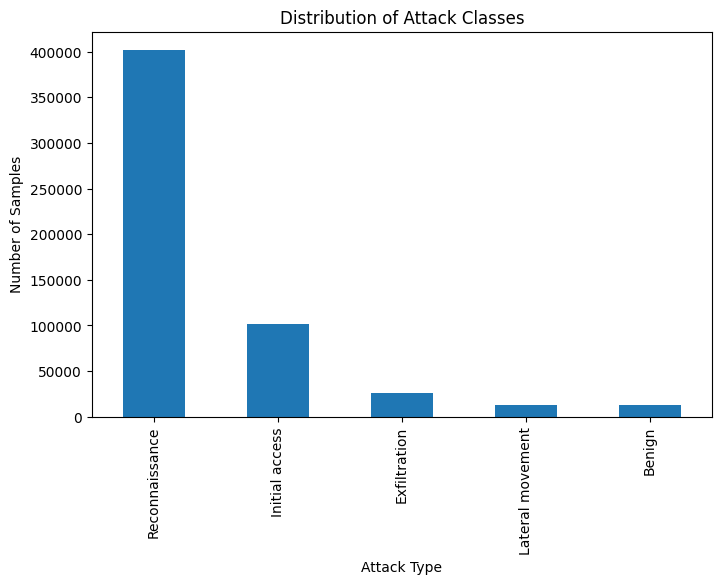

In [ ]:
import matplotlib.pyplot as plt

df["Label"].value_counts().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Distribution of Attack Classes")
plt.xlabel("Attack Type")
plt.ylabel("Number of Samples")

plt.show()

In [ ]:
df["Label"].unique()

array(['Benign', 'Exfiltration', 'Initial access', 'Lateral movement',
       'Reconnaissance'], dtype=object)

# =====================================================
# Step 4 - Feature Analysis & Data Preprocessing
# =====================================================
###### Objective:
###### Prepare the dataset for machine learning by removing non-predictive features and separating the input features from the target labels.

###### Tasks:
###### - Identify categorical columns
###### - Remove unnecessary features
###### - Create feature matrix (X)
###### - Create target variable (y)

In [ ]:
# Check data types
df.dtypes.value_counts()



,count
float64,45
int64,34
object,5


In [ ]:
# View categorical columns
df.select_dtypes(include=['object']).columns

Index(['Flow ID', 'Src IP', 'Dst IP', 'Timestamp', 'Label'], dtype='object')

In [ ]:
# Remove columns that will not be used for training
X = df.drop(
    columns=[
        "Flow ID",
        "Src IP",
        "Dst IP",
        "Timestamp",
        "Label"
    ]
)

# Target variable
y = df["Label"]

In [ ]:
print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)
print(y.head())

Feature Matrix Shape: (554534, 79)
Target Shape: (554534,)
0    Benign
1    Benign
2    Benign
3    Benign
4    Benign
Name: Label, dtype: object


# =====================================================
# Step 5 - Encode Target Labels
# =====================================================

###### Objective:
###### Convert the target labels from text into numerical values so they can be used by machine learning models.

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

In [ ]:
print(label_encoder.classes_)

['Benign' 'Exfiltration' 'Initial access' 'Lateral movement'
 'Reconnaissance']


In [ ]:
print(y_encoded[:10])

[0 0 0 0 0 0 0 0 0 0]


In [ ]:
mapping = dict(zip(label_encoder.classes_,
                   label_encoder.transform(label_encoder.classes_)))

print(mapping)

{'Benign': np.int64(0), 'Exfiltration': np.int64(1), 'Initial access': np.int64(2), 'Lateral movement': np.int64(3), 'Reconnaissance': np.int64(4)}


# =====================================================
# Step 6 - Train/Test Split
# =====================================================

##### Objective:
##### Split the dataset into training and testing sets. The training data will be used to train the models,while the testing data will be used to evaluate them.

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

In [ ]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Features: (443627, 79)
Testing Features: (110907, 79)
Training Labels: (443627,)
Testing Labels: (110907,)


# =====================================================
# Step 7 - Decision Tree Model
# =====================================================
#
###### Objective:
###### Train and evaluate a Decision Tree classifier for Healthcare IoMT cyberattack detection.
#
###### Tasks:
###### - Create the model
###### - Train the model
###### - Make predictions
###### - Evaluate performance
#


In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
# Create the Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42
)

In [ ]:
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
# Make predictions using the testing data
y_pred_dt = dt_model.predict(X_test)

In [ ]:
print(y_pred_dt[:10])

[4 4 4 4 4 4 1 4 2 4]


In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
# Calculate Decision Tree accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print(f"Decision Tree Accuracy: {dt_accuracy:.4f}")

Decision Tree Accuracy: 0.9888


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=label_encoder.classes_
))

                  precision    recall  f1-score   support

          Benign       0.98      0.98      0.98      2469
    Exfiltration       0.94      0.94      0.94      5183
  Initial access       1.00      1.00      1.00     20418
Lateral movement       0.85      0.85      0.85      2500
  Reconnaissance       0.99      0.99      0.99     80337

        accuracy                           0.99    110907
       macro avg       0.95      0.95      0.95    110907
    weighted avg       0.99      0.99      0.99    110907



###### =====================================================
###### Step 7.7 - Decision Tree Confusion Matrix
###### =====================================================
#
###### Objective:
###### Visualize the Decision Tree predictions to identify
###### where the model correctly and incorrectly classified Healthcare IoMT traffic.
#

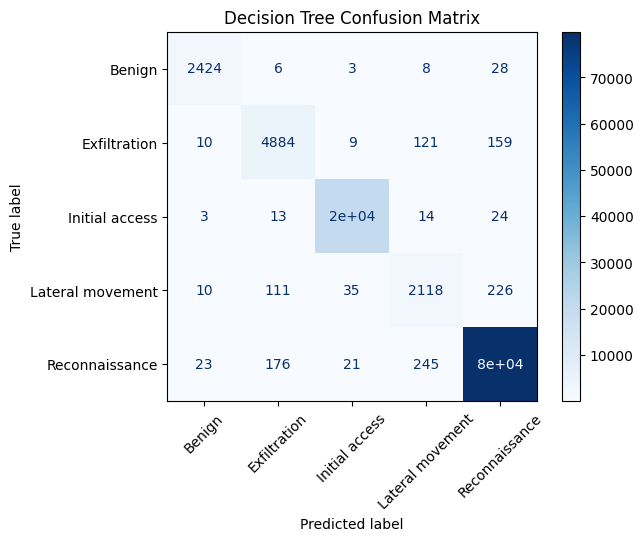

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

# =====================================================
# Decision Tree Summary
# =====================================================
#
# Model Accuracy: 98.88%
#
###### Observations:
###### - Excellent overall accuracy.
###### - Initial Access achieved the strongest performance.
###### - Lateral Movement produced the lowest F1-score.
###### - Most classification errors occurred between Lateral Movement and Reconnaissance.
#


# =====================================================
# Step 8 - Random Forest Model
# =====================================================
#
###### Objective:
###### Train and evaluate a Random Forest classifier for Healthcare IoMT cyberattack detection.
#
###### Tasks:
###### - Import the classifier
###### - Create the model
###### - Train the model
###### - Make predictions
###### - Evaluate performance
###### - Generate a confusion matrix
#


In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [ ]:
# Train the Random Forest model
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [ ]:
# Make predictions using the testing data
y_pred_rf = rf_model.predict(X_test)

In [ ]:
print(y_pred_rf[:10])

[4 4 4 4 4 4 1 4 2 4]


In [ ]:
# Calculate Random Forest accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")

Random Forest Accuracy: 0.9888


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=label_encoder.classes_
))

                  precision    recall  f1-score   support

          Benign       0.98      0.98      0.98      2469
    Exfiltration       0.95      0.92      0.94      5183
  Initial access       1.00      1.00      1.00     20418
Lateral movement       0.84      0.90      0.86      2500
  Reconnaissance       0.99      0.99      0.99     80337

        accuracy                           0.99    110907
       macro avg       0.95      0.96      0.95    110907
    weighted avg       0.99      0.99      0.99    110907



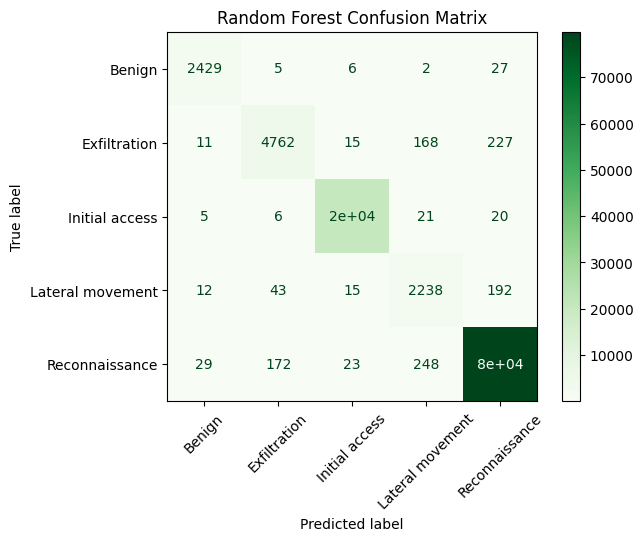

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")
plt.show()

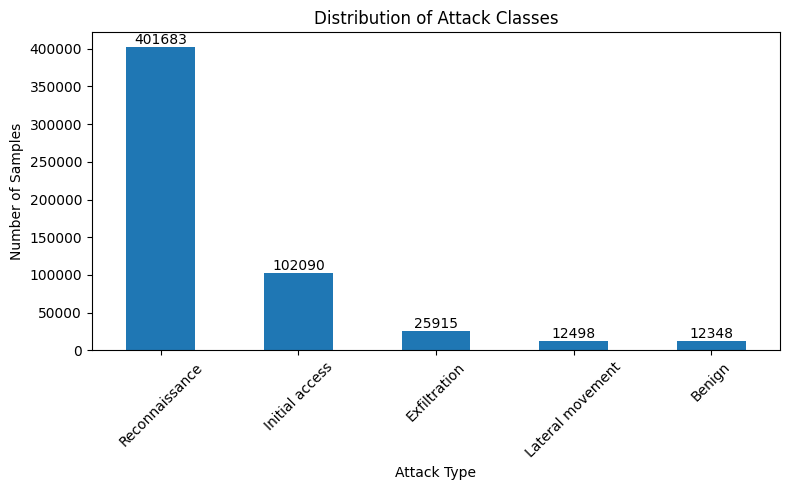

In [ ]:
ax = df["Label"].value_counts().plot(kind="bar", figsize=(8,5))

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Attack Classes")
plt.xlabel("Attack Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# =====================================================
# Step 9 - XGBoost Model
# =====================================================
#
###### Objective:
###### Train and evaluate an XGBoost classifier for
###### Healthcare IoMT cyberattack detection.
#
###### Tasks:
###### - Import the classifier
###### - Create the model
###### - Train the model
###### - Make predictions
###### - Evaluate performance
###### - Generate a confusion matrix
#
# =====================================================

In [ ]:
import xgboost
print(xgboost.__version__)

3.4.1


In [ ]:
from xgboost import XGBClassifier

In [ ]:
# Create the XGBoost model
xgb_model = XGBClassifier(
    objective="multi:softmax",
    num_class=5,
    n_estimators=100,
    random_state=42,
    eval_metric="mlogloss"
)

In [ ]:
# Train the XGBoost model
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None, num_class=5, ...)

In [ ]:
# Make predictions using the testing data
y_pred_xgb = xgb_model.predict(X_test)

In [ ]:
print(y_pred_xgb[:10])

[4 4 4 4 4 4 1 4 2 4]


In [ ]:
from sklearn.metrics import accuracy_score

# Calculate XGBoost accuracy
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

print(f"XGBoost Accuracy: {xgb_accuracy:.4f}")

XGBoost Accuracy: 0.9897


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=label_encoder.classes_
))

                  precision    recall  f1-score   support

          Benign       0.98      0.99      0.98      2469
    Exfiltration       0.96      0.94      0.95      5183
  Initial access       1.00      1.00      1.00     20418
Lateral movement       0.84      0.86      0.85      2500
  Reconnaissance       0.99      0.99      0.99     80337

        accuracy                           0.99    110907
       macro avg       0.95      0.96      0.96    110907
    weighted avg       0.99      0.99      0.99    110907



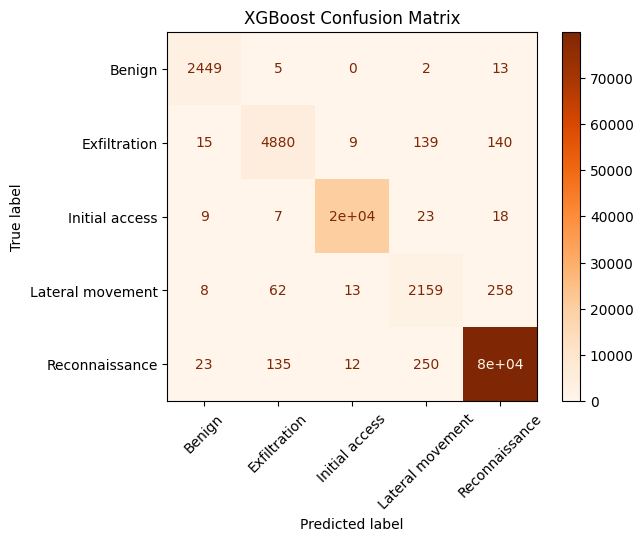

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    cmap="Oranges"
)

plt.title("XGBoost Confusion Matrix")
plt.show()

# =====================================================
# Step 10 - Model Comparison
# =====================================================
#
###### Objective:
###### Compare the performance of the Decision Tree,
###### Random Forest, and XGBoost models using common
###### evaluation metrics.
#
# =====================================================

In [ ]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        dt_accuracy,
        rf_accuracy,
        xgb_accuracy
    ]
})

comparison_df

,Model,Accuracy
0,Decision Tree,0.988774
1,Random Forest,0.988756
2,XGBoost,0.989712


In [ ]:
comparison_df["Accuracy"] = comparison_df["Accuracy"].map(lambda x: f"{x*100:.2f}%")

comparison_df

,Model,Accuracy
0,Decision Tree,98.88%
1,Random Forest,98.88%
2,XGBoost,98.97%


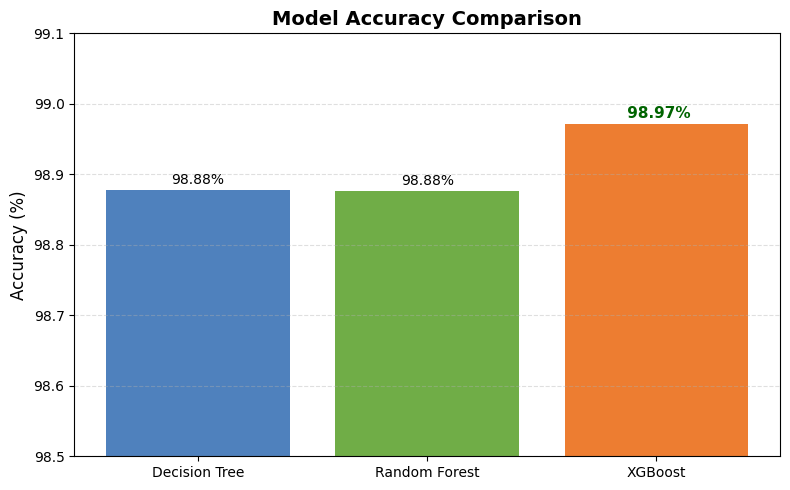

In [ ]:
import matplotlib.pyplot as plt

# Accuracy values (convert decimals to percentages)
accuracy_values = [
    dt_accuracy * 100,
    rf_accuracy * 100,
    xgb_accuracy * 100
]

# Model names
models = [
    "Decision Tree",
    "Random Forest",
    "XGBoost"
]

# Colors for each model
colors = [
    "#4F81BD",   # Blue - Decision Tree
    "#70AD47",   # Green - Random Forest
    "#ED7D31"    # Orange - XGBoost
]

# Create the figure
plt.figure(figsize=(8, 5))

bars = plt.bar(
    models,
    accuracy_values,
    color=colors
)

# Title and labels
plt.title("Model Accuracy Comparison", fontsize=14, fontweight="bold")
plt.ylabel("Accuracy (%)", fontsize=12)

# Set y-axis limits to highlight small differences
plt.ylim(98.5, 99.1)

# Add horizontal grid lines
plt.grid(axis="y", linestyle="--", alpha=0.4)

# Add percentage labels above each bar
for i, bar in enumerate(bars):
    height = bar.get_height()

    # Highlight XGBoost as the best-performing model
    if i == 2:
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.005,
            f" {height:.2f}%",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
            color="darkgreen"
        )
    else:
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.005,
            f"{height:.2f}%",
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.tight_layout()
plt.show()

# =====================================================
# Step 11 - Feature Importance Analysis
# =====================================================
#
##### Objective:
##### Identify the network traffic features that had the greatest influence on cyberattack detection.
#
# =====================================================

In [ ]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
37,Bwd Header Len,0.267070
36,Fwd Header Len,0.178030
46,SYN Flag Cnt,0.164275
1,Dst Port,0.050961
2,Protocol,0.048585
15,Bwd Pkt Len Std,0.038873
39,Bwd Pkts/s,0.029039
3,Flow Duration,0.027999
40,Pkt Len Min,0.021826
31,Bwd IAT Min,0.017834


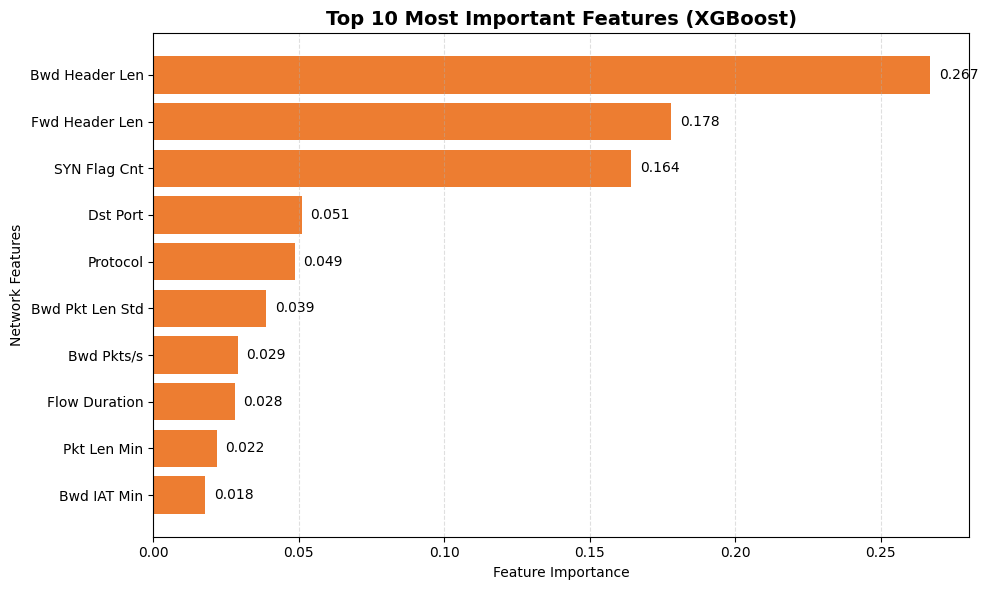

In [ ]:
import matplotlib.pyplot as plt

# Select the top 10 most important features
top_features = feature_importance.head(10)

plt.figure(figsize=(10,6))

bars = plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    color="#ED7D31"
)

plt.title(
    "Top 10 Most Important Features (XGBoost)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Feature Importance")
plt.ylabel("Network Features")

# Highest importance at the top
plt.gca().invert_yaxis()

# Add values to each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.003,
        bar.get_y() + bar.get_height()/2,
        f"{width:.3f}",
        va="center",
        fontsize=10
    )

plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# =====================================================
# Step 12 - Final Results Summary
# =====================================================

# Final Model Comparison

# Decision Tree
# Accuracy: 98.88%
# Strengths:
# - Simple and interpretable
# - Excellent overall accuracy

# Random Forest
# Accuracy: 98.88%
# Strengths:
# - Improved recall for Lateral Movement
# - More balanced classification

# XGBoost
# Accuracy: 98.97%
# Strengths:
# - Highest overall accuracy
# - Highest macro F1-score
# - Best overall model